# 02 - EEG Preprocessing
Turns the raw Excel trials into clean, equal-length arrays: channel alignment, NaN interpolation, CAR, 50 Hz notch, 8-30 Hz band-pass, crop/pad to a fixed duration, Z-score normalisation and automatic rejection of bad trials.

**Before running:** same `DATA_DIR`, `LABELS_CSV` and `FS` as in the EDA notebook. Run the cells from top to bottom. Results go to `processed_data/`.

### Cell 1 - Parameters
Imports the libraries and sets all preprocessing parameters in one place: filter band (8-30 Hz), notch frequency, the unified trial duration (`TARGET_DURATION_SEC = 4.0`), the rejection thresholds and the output folder.

In [1]:
import os, re, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import signal
warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

# ---------------- Paths / constants (EDIT HERE) ----------------
DATA_DIR   = "data/eeg_files"   # folder with the Excel trial files (sub-folders are searched too)
LABELS_CSV = "labels.csv"       # CSV with a 'label' column (Left / Right), same order as the sorted files
FS         = 256                # sampling rate in Hz  <-- set the real value of your recording
HEADER     = 0                  # Excel header row (None if files have no header)
NOTCH_HZ   = 50                 # power-line frequency
SEED       = 42

NON_EEG_HINTS = ("TIME", "LABEL", "UNNAMED", "INDEX")   # columns that are not EEG channels

# ---------------- Helper functions ----------------
def natural_key(path):
    """Sort key: trial_2.xlsx comes before trial_10.xlsx."""
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", os.path.basename(path))]

def list_trial_files(data_dir):
    files = glob.glob(os.path.join(data_dir, "**", "*.xls*"), recursive=True)
    files = [f for f in files if not os.path.basename(f).startswith("~$")]
    return sorted(files, key=natural_key)

def read_trial(path):
    """One Excel file -> numeric DataFrame (rows = samples, columns = EEG channels, UPPER-CASE names)."""
    df = pd.read_excel(path, header=HEADER)
    df.columns = [str(c).strip().upper() for c in df.columns]
    df = df.drop(columns=[c for c in df.columns if any(h in c for h in NON_EEG_HINTS)])
    return df.apply(pd.to_numeric, errors="coerce")

def build_mapping():
    """Clean filename <-> label mapping (uses a 'filename' column if present, else the sorted file order)."""
    labels = pd.read_csv(LABELS_CSV)
    labels["label"] = labels["label"].astype(str).str.strip().str.capitalize()
    if "filename" in labels.columns:
        m = labels.copy()
        m["path"] = m["filename"].apply(lambda f: os.path.join(DATA_DIR, f))
    else:
        files = list_trial_files(DATA_DIR)
        assert len(files) == len(labels), (
            f"{len(files)} Excel files in '{DATA_DIR}' but {len(labels)} labels in '{LABELS_CSV}'. "
            "Check DATA_DIR or add a 'filename' column to the CSV.")
        m = pd.DataFrame({"filename": [os.path.basename(f) for f in files], "path": files, "label": labels["label"].values})
    m.insert(0, "trial_id", range(len(m)))
    return m

# ---------------- Preprocessing parameters ----------------
BP_LOW, BP_HIGH     = 8, 30      # band-pass limits (Hz) - motor mu/beta range
TARGET_DURATION_SEC = 4.0        # every trial is cropped / zero-padded to this length
MIN_DURATION_SEC    = 2.0        # trials shorter than this are rejected
MAX_NAN_FRAC        = 0.05       # reject a trial if more than 5% of its values are NaN
FLAT_STD            = 1e-6       # std below this = flat channel -> trial rejected
PTP_MAD_K           = 5.0        # reject trials whose peak-to-peak amplitude is > median + K * robust-std
ZSCORE_MODE         = "channel"  # "channel" = z-score every channel separately | "global" = one mean/std per trial
LABEL_MAP           = {"Left": 0, "Right": 1}
OUT_DIR             = "processed_data"
TARGET_LEN          = int(TARGET_DURATION_SEC * FS)
print("Parameters OK | target length =", TARGET_LEN, "samples")

Parameters OK | target length = 1024 samples


### Cell 2 - Channel Alignment
Builds the filename-label mapping, reads the header of every file (in parallel) and chooses the most common channel layout as the reference `CHANNELS`. Later every trial is reordered to this list, so all trials have the same channels in the same order.

In [2]:
mapping = build_mapping()

def read_layout(path):
    df = pd.read_excel(path, header=HEADER, nrows=0)
    cols = [str(c).strip().upper() for c in df.columns]
    return tuple(c for c in cols if not any(h in c for h in NON_EEG_HINTS))

layouts = pd.Series(Parallel(n_jobs=-1)(delayed(read_layout)(p) for p in mapping["path"]))
CHANNELS = list(layouts.mode()[0])
print("Reference channels (%d):" % len(CHANNELS), CHANNELS)
print("Files with a different layout:", int((layouts != layouts.mode()[0]).sum()))
assert "C3" in CHANNELS and "C4" in CHANNELS, "C3/C4 are missing from the channel list"

Reference channels (8): ['C3', 'C4', 'F3', 'F4', 'P3', 'P4', 'O1', 'O2']
Files with a different layout: 0


### Cell 3 - Cleaning & Filtering Functions
Defines the signal-processing building blocks: NaN interpolation, Common Average Reference (CAR), a 50 Hz notch filter and a zero-phase Butterworth band-pass filter (8-30 Hz). All functions take an array of shape `(samples, channels)`.

In [3]:
def interpolate_nans(x):
    """Fill NaN gaps linearly along time; a channel that is all-NaN becomes zeros (caught later as flat)."""
    x = x.copy()
    for k in range(x.shape[1]):
        bad = np.isnan(x[:, k])
        if bad.all():
            x[:, k] = 0
        elif bad.any():
            x[bad, k] = np.interp(np.flatnonzero(bad), np.flatnonzero(~bad), x[~bad, k])
    return x

def common_average_reference(x):
    return x - x.mean(axis=1, keepdims=True)

_b_notch, _a_notch = signal.iirnotch(NOTCH_HZ, 30, fs=FS)
def notch_filter(x):
    return signal.filtfilt(_b_notch, _a_notch, x, axis=0)

_sos_bp = signal.butter(4, [BP_LOW, BP_HIGH], btype="band", fs=FS, output="sos")
def bandpass_filter(x):
    return signal.sosfiltfilt(_sos_bp, x, axis=0)
print("Filters ready: notch", NOTCH_HZ, "Hz + band-pass", BP_LOW, "-", BP_HIGH, "Hz")

Filters ready: notch 50 Hz + band-pass 8 - 30 Hz


### Cell 4 - Length & Scale Standardization
Defines `standardize_trial`, which (1) crops long trials to `TARGET_LEN` samples, (2) applies Z-score normalisation using only the real samples (channel-wise by default), and (3) zero-pads short trials at the end, so the padding never affects the statistics.

In [4]:
def standardize_trial(x):
    x = x[:TARGET_LEN]                                     # crop (keeps the beginning of the trial)
    if ZSCORE_MODE == "channel":
        mu, sd = x.mean(axis=0, keepdims=True), x.std(axis=0, keepdims=True)
    else:                                                  # one shared mean/std keeps the C3-vs-C4 amplitude relation
        mu, sd = x.mean(), x.std()
    x = (x - mu) / (sd + 1e-8)
    if len(x) < TARGET_LEN:                                # zero-pad after normalisation
        x = np.vstack([x, np.zeros((TARGET_LEN - len(x), x.shape[1]))])
    return x
print("Standardization ready | mode =", ZSCORE_MODE)

Standardization ready | mode = channel


### Cell 5 - Batch Processing & Artifact Rejection
Runs the full pipeline on every file in parallel: align channels -> reject (too short / too many NaNs / flat channel) -> interpolate NaNs -> CAR -> notch -> band-pass -> crop/pad + Z-score. Then trials with extreme peak-to-peak amplitude (robust median + MAD rule) are rejected, and the kept trials are stacked into `X` with shape `(N_trials, N_channels, N_samples)`.

In [5]:
def process_trial(path):
    df = read_trial(path)
    miss = [c for c in CHANNELS if c not in df.columns]
    if miss:
        return {"status": "missing_channels", "detail": ",".join(miss)}
    x = df[CHANNELS].values.astype("float64")
    if len(x) < MIN_DURATION_SEC * FS:
        return {"status": "too_short", "detail": f"{len(x) / FS:.2f}s"}
    nan_frac = float(np.isnan(x).mean())
    if nan_frac > MAX_NAN_FRAC:
        return {"status": "too_many_nans", "detail": f"{nan_frac:.1%}"}
    x = interpolate_nans(x)
    if (x.std(axis=0) < FLAT_STD).any():
        return {"status": "flat_channel", "detail": ",".join(np.array(CHANNELS)[x.std(axis=0) < FLAT_STD])}
    x = bandpass_filter(notch_filter(common_average_reference(x)))
    ptp = float(np.ptp(x, axis=0).max())
    return {"status": "ok", "x": standardize_trial(x).T.astype("float32"), "ptp": ptp}

res = Parallel(n_jobs=-1, verbose=5)(delayed(process_trial)(p) for p in mapping["path"])
status = pd.Series([r["status"] for r in res]); detail = pd.Series([r.get("detail", "") for r in res])

ptp = np.array([r.get("ptp", np.nan) for r in res])                      # dataset-level amplitude rejection
med = np.nanmedian(ptp); rob_std = 1.4826 * np.nanmedian(np.abs(ptp - med))
too_big = (status == "ok").values & (ptp > med + PTP_MAD_K * rob_std)
status[too_big] = "artifact_amplitude"; detail[too_big] = [f"ptp={v:.1f}" for v in ptp[too_big]]

kept = np.flatnonzero((status == "ok").values)
X = np.stack([res[i]["x"] for i in kept])                                 # (N_trials, N_channels, N_samples)
y = mapping["label"].iloc[kept].map(LABEL_MAP).values.astype("int64")
excluded = mapping.loc[status != "ok", ["trial_id", "filename", "label"]].assign(reason=status[status != "ok"].values, detail=detail[status != "ok"].values)

print("X:", X.shape, "| y:", y.shape, "| class counts [Left, Right]:", np.bincount(y).tolist())
print("Excluded trials:", len(excluded)); print(excluded["reason"].value_counts().to_string() if len(excluded) else "none")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:    5.2s
[Parallel(n_jobs=-1)]: Done  56 tasks      | elapsed:    7.1s
[Parallel(n_jobs=-1)]: Done 146 tasks      | elapsed:   10.0s
[Parallel(n_jobs=-1)]: Done 272 tasks      | elapsed:   14.9s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:   21.3s
[Parallel(n_jobs=-1)]: Done 632 tasks      | elapsed:   28.0s
[Parallel(n_jobs=-1)]: Done 866 tasks      | elapsed:   35.5s
[Parallel(n_jobs=-1)]: Done 1136 tasks      | elapsed:   45.1s
[Parallel(n_jobs=-1)]: Done 1442 tasks      | elapsed:   57.3s
[Parallel(n_jobs=-1)]: Done 1784 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 2162 tasks      | elapsed:  1.5min


X: (2400, 8, 1024) | y: (2400,) | class counts [Left, Right]: [1187, 1213]
Excluded trials: 0
none


[Parallel(n_jobs=-1)]: Done 2400 out of 2400 | elapsed:  1.7min finished


### Cell 6 - Before vs After Plot
Visual sanity check on channel C3: for one `Left` and one `Right` trial, the raw signal (left column) is compared with the processed signal (right column: filtered 8-30 Hz, CAR, Z-scored).

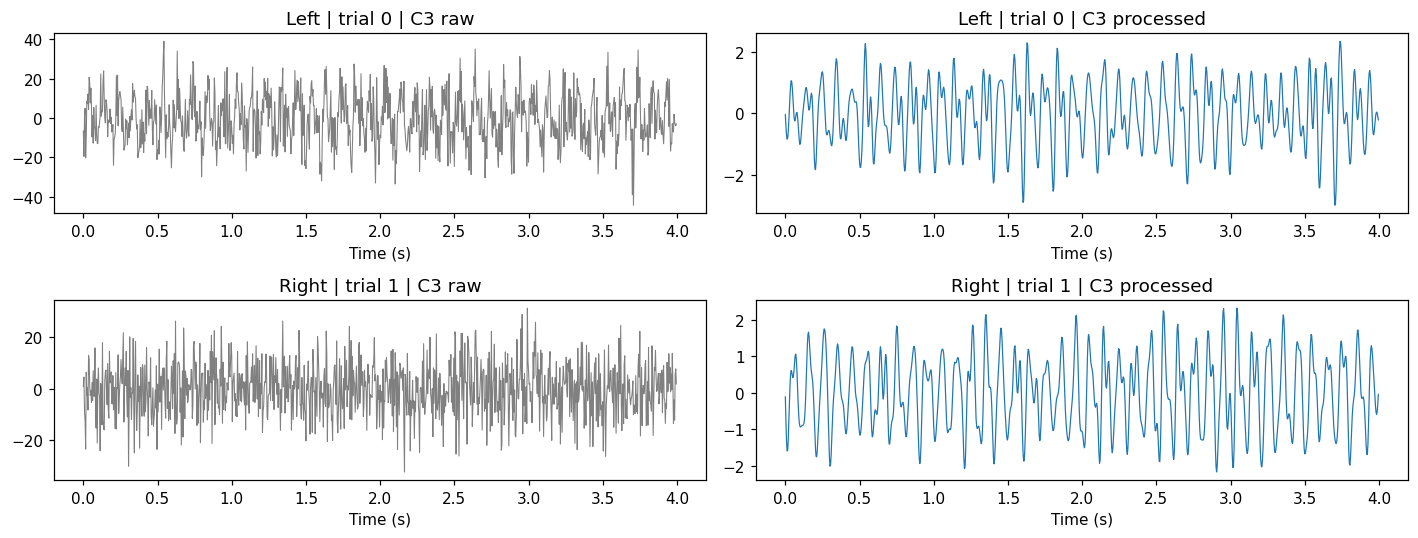

In [6]:
c3 = CHANNELS.index("C3")
fig, axes = plt.subplots(2, 2, figsize=(13, 5))
for row, cls in enumerate(["Left", "Right"]):
    j = int(np.flatnonzero(mapping["label"].iloc[kept].values == cls)[0])      # first kept trial of this class
    raw = read_trial(mapping["path"].iloc[kept[j]])[CHANNELS].values[:, c3]
    axes[row, 0].plot(np.arange(len(raw)) / FS, raw, color="gray", lw=0.7)
    axes[row, 0].set_title(f"{cls} | trial {kept[j]} | C3 raw")
    axes[row, 1].plot(np.arange(X.shape[2]) / FS, X[j, c3], color="tab:blue", lw=0.8)
    axes[row, 1].set_title(f"{cls} | trial {kept[j]} | C3 processed")
    for ax in axes[row]: ax.set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

### Cell 7 - Save Outputs
Saves the final arrays `X_eeg.npy` and `y_eeg.npy`, the channel list, the label map, the kept-trial list and the log of excluded trials (with the reason) in the `processed_data/` folder, then reloads `X_eeg.npy` as a check.

In [7]:
os.makedirs(OUT_DIR, exist_ok=True)
np.save(f"{OUT_DIR}/X_eeg.npy", X)
np.save(f"{OUT_DIR}/y_eeg.npy", y)
json.dump(CHANNELS, open(f"{OUT_DIR}/channels.json", "w"))
json.dump({"label_map": LABEL_MAP, "fs": FS, "bandpass": [BP_LOW, BP_HIGH], "notch_hz": NOTCH_HZ,
           "target_duration_sec": TARGET_DURATION_SEC, "zscore_mode": ZSCORE_MODE}, open(f"{OUT_DIR}/config.json", "w"), indent=2)
mapping.iloc[kept][["trial_id", "filename", "label"]].to_csv(f"{OUT_DIR}/kept_trials.csv", index=False)
excluded.to_csv(f"{OUT_DIR}/excluded_trials.csv", index=False)
print("Saved to", OUT_DIR, "->", sorted(os.listdir(OUT_DIR)))
print("Reload check:", np.load(f"{OUT_DIR}/X_eeg.npy").shape, np.load(f"{OUT_DIR}/y_eeg.npy").shape)

Saved to processed_data -> ['X_eeg.npy', 'channels.json', 'config.json', 'excluded_trials.csv', 'kept_trials.csv', 'y_eeg.npy']
Reload check: (2400, 8, 1024) (2400,)
